# Practical No. 7
## Classification using Logistic Regression and K-Nearest Neighbors (KNN)

### Aim
To perform data preprocessing and implement Logistic Regression and KNN on the Iris dataset and evaluate using Accuracy, Precision, Recall, F1-Score, and Confusion Matrix.

## Dataset
**Iris Dataset** — 150 samples, 4 features, and 3 classes: Setosa, Versicolor, and Virginica.

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

## Load Dataset

In [35]:
iris = load_iris()

In [36]:
X = iris.data
y = iris.target

In [37]:
print(iris.feature_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [38]:
print(iris.target_names)

['setosa' 'versicolor' 'virginica']


In [39]:
print('Feature Shape:', X.shape)
print('Target Shape:', y.shape)

Feature Shape: (150, 4)
Target Shape: (150,)


In [40]:
df = pd.DataFrame(X, columns=iris.feature_names)
df['Target'] = y
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Target             150 non-null    int32  
dtypes: float64(4), int32(1)
memory usage: 5.4 KB


In [42]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Target               0
dtype: int64

## Split Dataset

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [44]:
print('Training Samples:', X_train.shape[0])
print('Testing Samples:', X_test.shape[0])

Training Samples: 120
Testing Samples: 30


## Feature Scaling

In [45]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Logistic Regression

In [46]:
lr = LogisticRegression(max_iter=1000)

In [47]:
lr.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [48]:
lr_pred = lr.predict(X_test)

In [49]:
lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred, average='weighted')
lr_recall = recall_score(y_test, lr_pred, average='weighted')
lr_f1 = f1_score(y_test, lr_pred, average='weighted')
print('Accuracy :', lr_accuracy)
print('Precision:', lr_precision)
print('Recall   :', lr_recall)
print('F1-Score :', lr_f1)

Accuracy : 0.9333333333333333
Precision: 0.9333333333333333
Recall   : 0.9333333333333333
F1-Score : 0.9333333333333333


In [50]:
print(classification_report(y_test, lr_pred, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



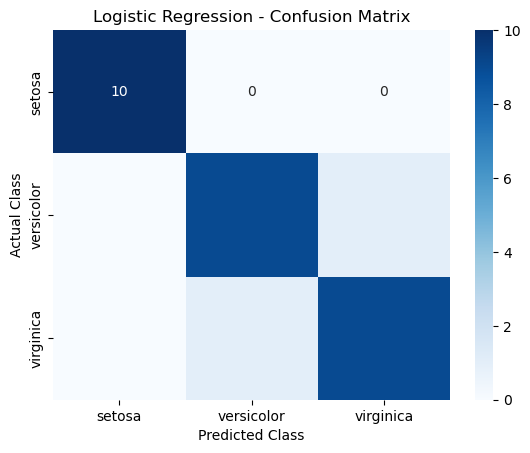

In [21]:
cm_lr = confusion_matrix(y_test, lr_pred)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

# K-Nearest Neighbors (KNN)

In [22]:
knn = KNeighborsClassifier(n_neighbors=5)

In [23]:
knn.fit(X_train, y_train)

KNeighborsClassifier()

In [25]:
knn_pred = knn.predict(X_test)

In [26]:
knn_accuracy = accuracy_score(y_test, knn_pred)
knn_precision = precision_score(y_test, knn_pred, average='weighted')
knn_recall = recall_score(y_test, knn_pred, average='weighted')
knn_f1 = f1_score(y_test, knn_pred, average='weighted')
print('Accuracy :', knn_accuracy)
print('Precision:', knn_precision)
print('Recall   :', knn_recall)
print('F1-Score :', knn_f1)

Accuracy : 0.9333333333333333
Precision: 0.9444444444444445
Recall   : 0.9333333333333333
F1-Score : 0.9326599326599326


In [27]:
print(classification_report(y_test, knn_pred, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



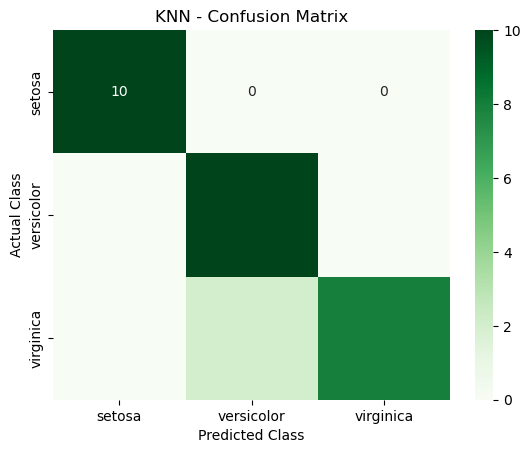

In [28]:
cm_knn = confusion_matrix(y_test, knn_pred)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Greens', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title('KNN - Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

## Model Comparison

In [29]:
comparison = pd.DataFrame({'Model':['Logistic Regression','KNN'],'Accuracy':[lr_accuracy,knn_accuracy],'Precision':[lr_precision,knn_precision],'Recall':[lr_recall,knn_recall],'F1-Score':[lr_f1,knn_f1]})
comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,KNN,0.933333,0.944444,0.933333,0.932660


In [30]:
comparison_percentage = comparison.copy()
for column in ['Accuracy','Precision','Recall','F1-Score']:
    comparison_percentage[column] = (comparison_percentage[column] * 100).round(2)
comparison_percentage

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,93.33,93.33,93.33,93.33
1,KNN,93.33,94.44,93.33,93.27


## Result
Successfully implemented Logistic Regression and KNN on the Iris dataset. Both models were evaluated using Accuracy, Precision, Recall, F1-Score, and Confusion Matrix, and their performances were compared.